# Breast Cancer Classification (Wisconsin Diagnostic Dataset)

**Goal:** predict whether a breast tumor is malignant or benign from cell-nucleus measurements.

*AI tools were used for code assistance and drafting. All analysis and interpretation were reviewed by me.*

## 1. Load data

In [1]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

data = load_breast_cancer(as_frame=True)
df = data.frame
print(df.shape)
print(df['target'].value_counts().rename({0: 'malignant', 1: 'benign'}))
df.head()

(569, 31)
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 2. Exploratory plot

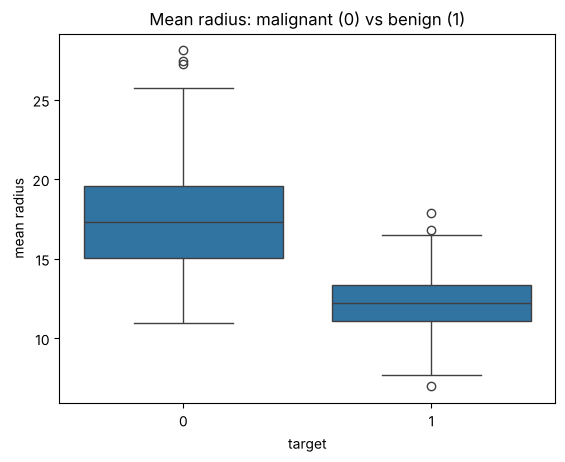

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x="target", y="mean radius", data=df)
plt.title("Mean radius: malignant (0) vs benign (1)")
plt.show()

## 3. Train Random Forest

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X = df.drop("target", axis=1)
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

Accuracy: 0.956


## 4. Confusion matrix, precision, recall, F1
In medical work, missing a malignant tumor (false negative) is costlier than a false alarm, so accuracy alone is not enough.

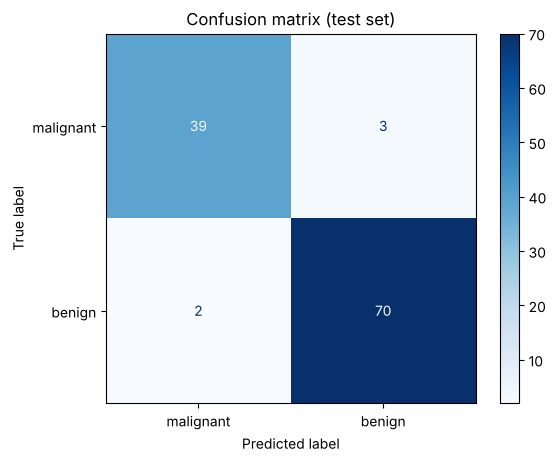

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

## 5. Cross-validation
A single train/test split can be lucky or unlucky. 5-fold cross-validation gives a more reliable estimate.

In [5]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(RandomForestClassifier(random_state=42), X, y, cv=5)
print("CV accuracy per fold:", scores.round(3))
print(f"Mean: {scores.mean():.3f} (+/- {scores.std():.3f})")

CV accuracy per fold: [0.921 0.939 0.982 0.965 0.973]
Mean: 0.956 (+/- 0.023)


## 6. Model comparison

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM": make_pipeline(StandardScaler(), SVC()),
}

results = {}
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=5)
    results[name] = (s.mean(), s.std())

res_df = pd.DataFrame(results, index=["Mean CV accuracy", "Std"]).T.round(3)
res_df

,Mean CV accuracy,Std
Random Forest,0.956,0.023
Logistic Regression,0.981,0.007
SVM,0.974,0.015


## 7. Feature importance (Random Forest)

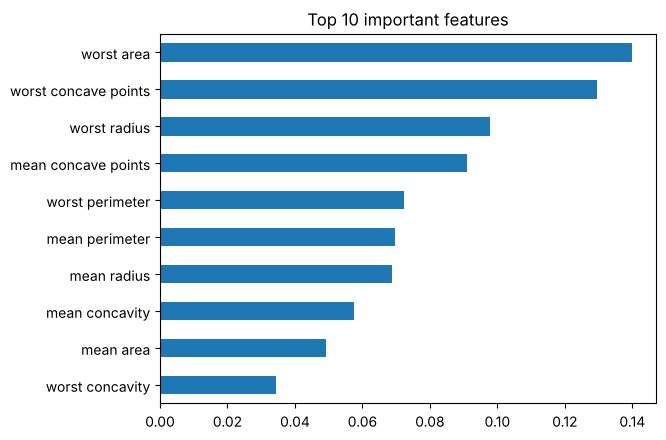

In [7]:
importance = pd.Series(model.feature_importances_, index=X.columns)
top10 = importance.sort_values(ascending=False).head(10)
top10.sort_values().plot(kind="barh", title="Top 10 important features")
plt.show()

## 8. Limitations
- Small dataset (569 samples) from a single source.
- Measurements are already extracted from images; this is not image-based diagnosis.
- Results are for learning and research demonstration only and are **not clinically validated**.
- Feature importance shows association in this dataset, not biological causation.